In [1]:
# 1. Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

In [3]:
# 2. Load dataset
df = pd.read_csv("sales_data_sample.csv", encoding="latin1")

print("Dataset Shape:", df.shape)
print(df.head())


Dataset Shape: (2823, 25)
   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1             59 rue

In [4]:
# 3. Data preprocessing
df.drop_duplicates(inplace=True)

# Select numerical features useful for sales clustering
features = [
    'QUANTITYORDERED',
    'PRICEEACH',
    'SALES',
    'MSRP'
]

X = df[features].copy()

# Handle missing values
X = X.fillna(X.median())

In [5]:
# 4. Feature scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [6]:
# 5. Find optimal clusters using Elbow Method
inertia = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)


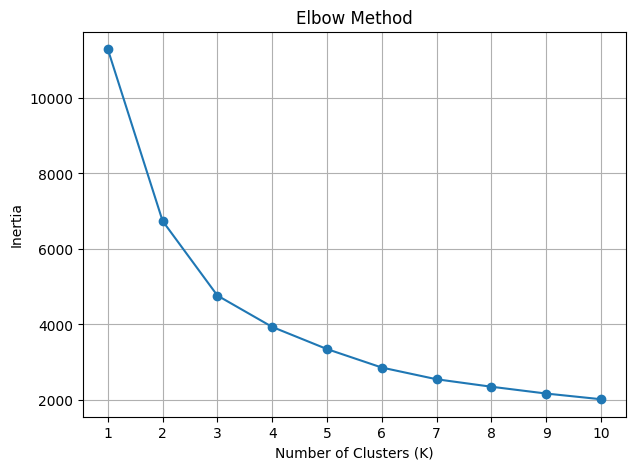

In [7]:
# Plot Elbow graph
plt.figure(figsize=(7, 5))
plt.plot(range(1, 11), inertia, marker='o')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.xticks(range(1, 11))
plt.grid()
plt.show()

In [8]:
# 6. Apply K-Means using selected K
# Choose K by observing the elbow graph
optimal_k = 3

start_time = time.time()

kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

df['Cluster'] = kmeans.fit_predict(X_scaled)

execution_time = time.time() - start_time

In [9]:
# 7. Display cluster results
print("\nCluster Counts:")
print(df['Cluster'].value_counts().sort_index())

print("\nCluster Centers:")
centers = scaler.inverse_transform(kmeans.cluster_centers_)
print(pd.DataFrame(centers, columns=features).round(2))

print("\nExecution Time:", round(execution_time, 4), "seconds")


Cluster Counts:
Cluster
0    975
1    852
2    996
Name: count, dtype: int64

Cluster Centers:
   QUANTITYORDERED  PRICEEACH    SALES    MSRP
0            35.21      59.55  2101.08   64.15
1            43.73      97.49  5722.35  127.95
2            27.61      95.43  3123.73  113.23

Execution Time: 0.0258 seconds


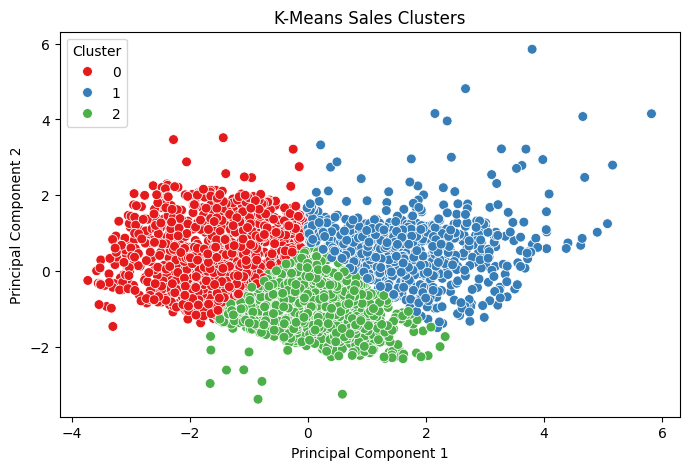

In [10]:
# 8. Visualize clusters using PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 5))
sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=df['Cluster'],
    palette='Set1',
    s=50
)
plt.title("K-Means Sales Clusters")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

In [11]:
# 9. Analyze clusters
print("\nCluster Analysis:")
print(df.groupby('Cluster')[features].mean().round(2))



Cluster Analysis:
         QUANTITYORDERED  PRICEEACH    SALES    MSRP
Cluster                                             
0                  35.21      59.55  2101.08   64.15
1                  43.72      97.48  5720.08  127.89
2                  27.60      95.44  3123.06  113.27
